In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 31 - FEATURE SCALING VALIDATION")
print("=" * 60)

print("\nLibraries imported successfully!")
print("Today's Goal: Validate the scaled student feature dataset.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - FEATURE SCALING VALIDATION

Libraries imported successfully!
Today's Goal: Validate the scaled student feature dataset.


In [2]:
# DAY 31 - LOAD SCALED DATASET

current_dir = Path.cwd()

possible_paths = [
    current_dir / "day30_scaled_student_features.csv",
    current_dir.parent / "day30_scaled_student_features.csv",
    current_dir.parent.parent / "day30_scaled_student_features.csv",
    current_dir / "Data" / "day30_scaled_student_features.csv",
    current_dir.parent / "Data" / "day30_scaled_student_features.csv"
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is not None:
    df_scaled = pd.read_csv(dataset_path)

    print("Scaled dataset loaded successfully!")
    print("File location:", dataset_path.resolve())
    print("Dataset shape:", df_scaled.shape)

    print("\nColumn Names:")
    print(df_scaled.columns.tolist())

    print("\nFirst 5 Records:")
    display(df_scaled.head())

else:
    print("Scaled dataset file not found.")
    print("Current directory:", current_dir)
    print("Please check whether Day 30's save cell ran successfully.")

Scaled dataset loaded successfully!
File location: C:\Users\Bagmita\OneDrive\Desktop\Project\day30_scaled_student_features.csv
Dataset shape: (3, 4)

Column Names:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

First 5 Records:


,study_hours,attendance,previous_score,assignments_completed
0,1.364121,1.364121,1.364121,0.233786
1,-1.005141,-1.005141,-1.005141,1.091001
2,-0.358979,-0.358979,-0.358979,-1.324787


In [3]:
# DAY 31 - DATASET STRUCTURE VALIDATION

if "df_scaled" in globals() and not df_scaled.empty:
    print("=" * 60)
    print("STUDENT PERFORMANCE PREDICTION SYSTEM")
    print("DAY 31 - DATASET STRUCTURE VALIDATION")
    print("=" * 60)

    print("\n1. Dataset Information:")
    df_scaled.info()

    print("\n2. Data Types:")
    display(df_scaled.dtypes.to_frame("Data Type"))

    print("\n3. Missing Values:")
    display(
        df_scaled.isnull()
        .sum()
        .to_frame("Missing Count")
    )

    print("\n4. Duplicate Rows:", df_scaled.duplicated().sum())

    print("\n5. Dataset Dimensions:")
    print("Rows:", df_scaled.shape[0])
    print("Columns:", df_scaled.shape[1])

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - DATASET STRUCTURE VALIDATION

1. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            3 non-null      float64
 1   attendance             3 non-null      float64
 2   previous_score         3 non-null      float64
 3   assignments_completed  3 non-null      float64
dtypes: float64(4)
memory usage: 228.0 bytes

2. Data Types:


,Data Type
study_hours,float64
attendance,float64
previous_score,float64
assignments_completed,float64



3. Missing Values:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



4. Duplicate Rows: 0

5. Dataset Dimensions:
Rows: 3
Columns: 4


In [4]:
# DAY 31 - SCALED VALUE VALIDATION

if "df_scaled" in globals() and not df_scaled.empty:
    print("=" * 60)
    print("SCALED FEATURE VALUE VALIDATION")
    print("=" * 60)

    # Convert values to numeric for validation
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Check non-numeric values
    non_numeric_counts = df_scaled.notna().sum() - df_numeric.notna().sum()

    print("\n1. Non-numeric values in each column:")
    display(non_numeric_counts.to_frame("Non-numeric Count"))

    # Check missing values
    print("\n2. Missing values:")
    display(df_numeric.isnull().sum().to_frame("Missing Count"))

    # Check infinite values
    numeric_array = df_numeric.to_numpy(dtype=float)

    infinite_counts = pd.Series(
        np.isinf(numeric_array).sum(axis=0),
        index=df_numeric.columns,
        name="Infinite Count"
    )

    print("\n3. Infinite values:")
    display(infinite_counts.to_frame())

    # Overall validation result
    has_non_numeric = non_numeric_counts.sum() > 0
    has_missing = df_numeric.isnull().any().any()
    has_infinite = np.isinf(numeric_array).any()

    print("\n4. Validation Result:")

    if not has_non_numeric and not has_missing and not has_infinite:
        print("PASS: All feature values are numeric and finite.")
    else:
        print("REVIEW REQUIRED: Some invalid values were found.")
        print("Check the tables above before proceeding.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

SCALED FEATURE VALUE VALIDATION

1. Non-numeric values in each column:


,Non-numeric Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



2. Missing values:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



3. Infinite values:


,Infinite Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



4. Validation Result:
PASS: All feature values are numeric and finite.


In [5]:
# DAY 31 - VERIFY SCALING STATISTICS

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    ):
        print("=" * 60)
        print("SCALING STATISTICS VALIDATION")
        print("=" * 60)

        # Calculate statistics
        mean_values = df_numeric.mean()
        std_values = df_numeric.std(ddof=0)

        stats = pd.DataFrame({
            "Mean": mean_values,
            "Population Std": std_values,
            "Mean Near Zero": np.isclose(
                mean_values, 0, atol=0.01
            ),
            "Std Near One or Zero": (
                np.isclose(std_values, 1, atol=0.01)
                | np.isclose(std_values, 0, atol=0.01)
            )
        })

        display(stats.round(4))

        print("\nInterpretation:")
        print("- Mean should be approximately zero.")
        print("- Non-constant features should have std approximately one.")
        print("- Constant features may have std equal to zero.")

        means_valid = np.isclose(
            mean_values.to_numpy(), 0, atol=0.01
        ).all()

        std_valid = (
            np.isclose(std_values.to_numpy(), 1, atol=0.01)
            | np.isclose(std_values.to_numpy(), 0, atol=0.01)
        ).all()

        if means_valid and std_valid:
            print("\nPASS: Scaling statistics look correct.")
        else:
            print("\nREVIEW: Some statistics need further inspection.")

    else:
        print("Dataset contains missing, non-numeric, or infinite values.")
        print("Please review the previous validation cell.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

SCALING STATISTICS VALIDATION


,Mean,Population Std,Mean Near Zero,Std Near One or Zero
study_hours,-0.0,1.0,True,True
attendance,0.0,1.0,True,True
previous_score,-0.0,1.0,True,True
assignments_completed,0.0,1.0,True,True



Interpretation:
- Mean should be approximately zero.
- Non-constant features should have std approximately one.
- Constant features may have std equal to zero.

PASS: Scaling statistics look correct.


STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - SCALED FEATURE DISTRIBUTION


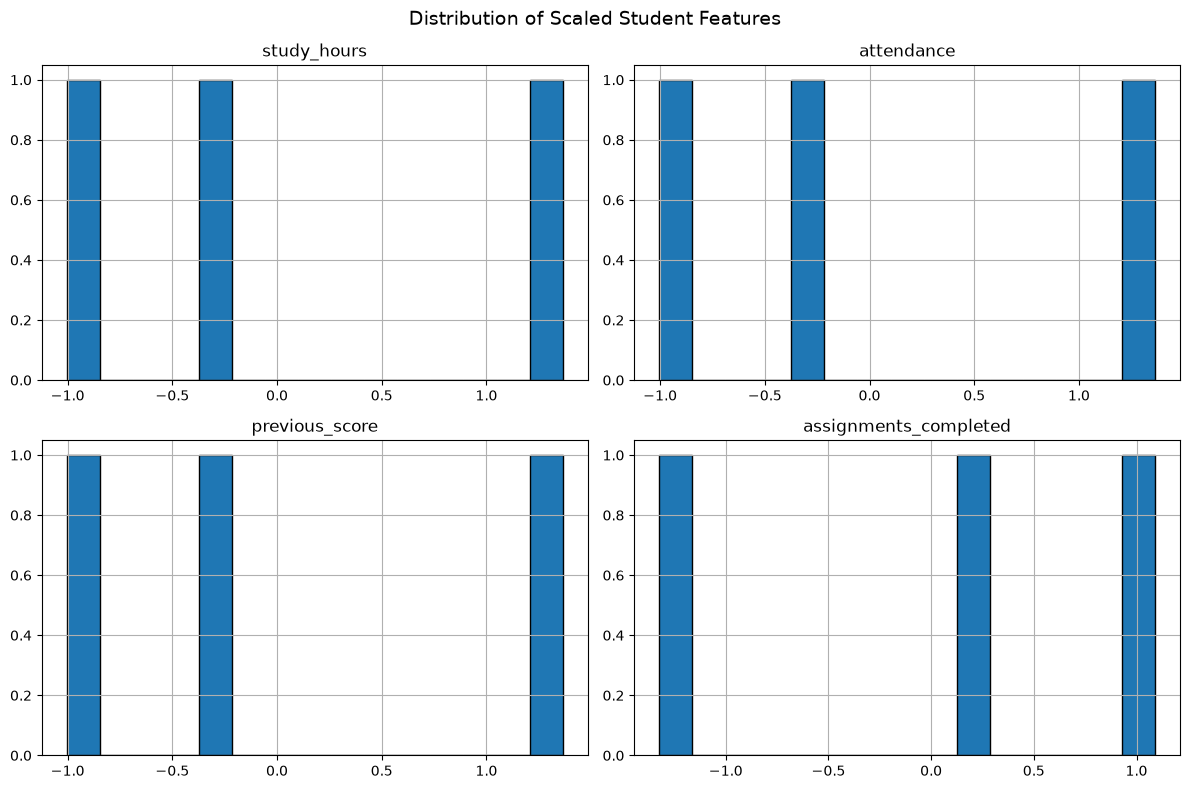


Features visualized:
- study_hours
- attendance
- previous_score
- assignments_completed

Visualization completed successfully!


In [6]:
# DAY 31 - SCALED FEATURE DISTRIBUTION

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    ):
        print("=" * 60)
        print("STUDENT PERFORMANCE PREDICTION SYSTEM")
        print("DAY 31 - SCALED FEATURE DISTRIBUTION")
        print("=" * 60)

        number_of_features = len(df_numeric.columns)

        df_numeric.hist(
            figsize=(12, 8),
            bins=15,
            edgecolor="black"
        )

        import matplotlib.pyplot as plt

        plt.suptitle(
            "Distribution of Scaled Student Features",
            fontsize=14
        )
        plt.tight_layout()
        plt.show()

        print("\nFeatures visualized:")
        for feature in df_numeric.columns:
            print("-", feature)

        print("\nVisualization completed successfully!")

    else:
        print("Invalid values found in the dataset.")
        print("Please review Cell 4 before plotting.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - FEATURE CORRELATION ANALYSIS

Correlation Matrix:


,study_hours,attendance,previous_score,assignments_completed
study_hours,1.000,1.000,1.000,-0.101
attendance,1.000,1.000,1.000,-0.101
previous_score,1.000,1.000,1.000,-0.101
assignments_completed,-0.101,-0.101,-0.101,1.000


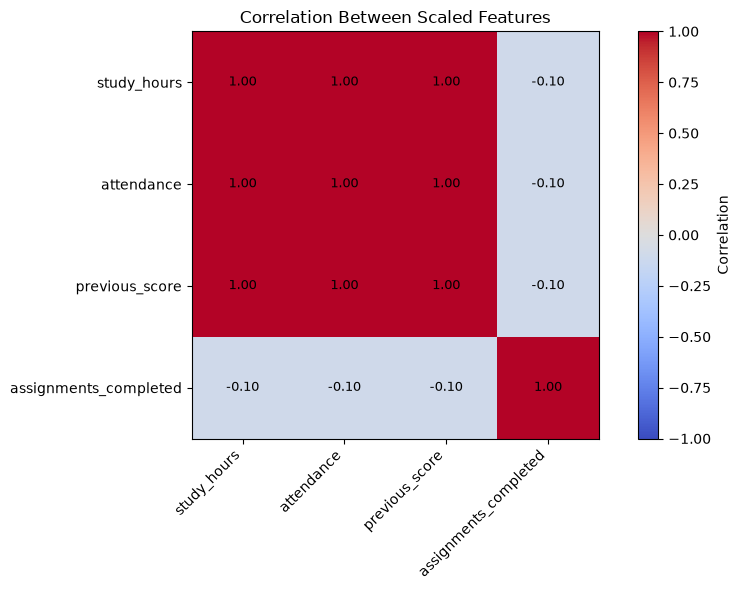


Correlation analysis completed!


In [7]:
# DAY 31 - FEATURE CORRELATION ANALYSIS

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    ):
        print("=" * 60)
        print("STUDENT PERFORMANCE PREDICTION SYSTEM")
        print("DAY 31 - FEATURE CORRELATION ANALYSIS")
        print("=" * 60)

        # Calculate correlation matrix
        correlation_matrix = df_numeric.corr()

        print("\nCorrelation Matrix:")
        display(correlation_matrix.round(3))

        # Plot correlation heatmap using Matplotlib
        fig, ax = plt.subplots(figsize=(9, 6))

        image = ax.imshow(
            correlation_matrix,
            cmap="coolwarm",
            vmin=-1,
            vmax=1
        )

        ax.set_xticks(range(len(correlation_matrix.columns)))
        ax.set_yticks(range(len(correlation_matrix.index)))

        ax.set_xticklabels(
            correlation_matrix.columns,
            rotation=45,
            ha="right"
        )
        ax.set_yticklabels(correlation_matrix.index)

        for i in range(len(correlation_matrix.index)):
            for j in range(len(correlation_matrix.columns)):
                ax.text(
                    j,
                    i,
                    f"{correlation_matrix.iloc[i, j]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9
                )

        ax.set_title("Correlation Between Scaled Features")
        fig.colorbar(image, ax=ax, label="Correlation")
        plt.tight_layout()
        plt.show()

        print("\nCorrelation analysis completed!")

    else:
        print("Dataset contains invalid values.")
        print("Please review Cell 4 before proceeding.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

In [8]:
# DAY 31 - HIGH CORRELATION DETECTION

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    ):
        print("=" * 60)
        print("HIGHLY CORRELATED FEATURE ANALYSIS")
        print("=" * 60)

        correlation_matrix = df_numeric.corr()

        # Keep only unique feature pairs
        upper_triangle = correlation_matrix.where(
            np.triu(
                np.ones(correlation_matrix.shape),
                k=1
            ).astype(bool)
        )

        threshold = 0.80

        high_correlation_pairs = (
            upper_triangle.stack()
            .loc[lambda values: values.abs() >= threshold]
            .reset_index()
        )

        high_correlation_pairs.columns = [
            "Feature 1",
            "Feature 2",
            "Correlation"
        ]

        print(f"\nCorrelation threshold: |r| >= {threshold}")

        if not high_correlation_pairs.empty:
            print("\nHighly correlated feature pairs:")
            display(
                high_correlation_pairs.round(3)
            )
        else:
            print("\nNo feature pairs exceeded the threshold.")

        print("\nInterpretation:")
        print("- Positive correlation indicates features tend to increase together.")
        print("- Negative correlation indicates one tends to decrease as the other increases.")
        print("- High correlation does not automatically mean a feature must be removed.")

    else:
        print("Invalid values found. Please review Cell 4.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

HIGHLY CORRELATED FEATURE ANALYSIS

Correlation threshold: |r| >= 0.8

Highly correlated feature pairs:


,Feature 1,Feature 2,Correlation
0,study_hours,attendance,1.0
1,study_hours,previous_score,1.0
2,attendance,previous_score,1.0



Interpretation:
- Positive correlation indicates features tend to increase together.
- Negative correlation indicates one tends to decrease as the other increases.
- High correlation does not automatically mean a feature must be removed.


In [9]:
# DAY 31 - SAVE FEATURE VALIDATION REPORT

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    ):
        print("=" * 60)
        print("SAVING DAY 31 VALIDATION REPORT")
        print("=" * 60)

        # Calculate validation information
        correlation_matrix = df_numeric.corr()

        upper_triangle = correlation_matrix.where(
            np.triu(
                np.ones(correlation_matrix.shape),
                k=1
            ).astype(bool)
        )

        high_pairs = (
            upper_triangle.stack()
            .loc[lambda values: values.abs() >= 0.80]
        )

        report_lines = [
            "STUDENT PERFORMANCE PREDICTION SYSTEM",
            "DAY 31 - FEATURE SCALING VALIDATION REPORT",
            "=" * 55,
            "",
            f"Dataset rows: {df_numeric.shape[0]}",
            f"Dataset features: {df_numeric.shape[1]}",
            f"Duplicate rows: {df_scaled.duplicated().sum()}",
            f"Missing values: {int(df_numeric.isnull().sum().sum())}",
            "",
            "FEATURE SCALING STATISTICS",
            "-" * 35,
            df_numeric.describe().to_string(),
            "",
            "CORRELATION MATRIX",
            "-" * 35,
            correlation_matrix.round(3).to_string(),
            "",
            "HIGH CORRELATION PAIRS (|r| >= 0.80)",
            "-" * 35,
            high_pairs.to_string() if not high_pairs.empty
            else "No feature pairs exceeded the threshold.",
            "",
            "Note: This report validates preprocessing statistics.",
            "It does not measure prediction accuracy."
        ]

        report_text = "\n".join(report_lines)

        # Save report in the current working directory
        report_path = (
            Path.cwd()
            / "day31_feature_scaling_validation_report.txt"
        )

        report_path.write_text(
            report_text,
            encoding="utf-8"
        )

        print("Report saved successfully!")
        print("File location:", report_path.resolve())
        print("\nReport Preview:")
        print(report_text[:2000])

    else:
        print("Cannot generate report because invalid values exist.")
        print("Please review Cell 4 and correct the dataset.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 first.")

SAVING DAY 31 VALIDATION REPORT
Report saved successfully!
File location: C:\Users\Bagmita\OneDrive\Desktop\Project\day31_feature_scaling_validation_report.txt

Report Preview:
STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - FEATURE SCALING VALIDATION REPORT

Dataset rows: 3
Dataset features: 4
Duplicate rows: 0
Missing values: 0

FEATURE SCALING STATISTICS
-----------------------------------
        study_hours    attendance  previous_score  assignments_completed
count  3.000000e+00  3.000000e+00    3.000000e+00           3.000000e+00
mean  -3.515706e-16  2.035409e-15   -1.165734e-15           4.588922e-15
std    1.224745e+00  1.224745e+00    1.224745e+00           1.224745e+00
min   -1.005141e+00 -1.005141e+00   -1.005141e+00          -1.324787e+00
25%   -6.820603e-01 -6.820603e-01   -6.820603e-01          -5.455006e-01
50%   -3.589791e-01 -3.589791e-01   -3.589791e-01           2.337860e-01
75%    5.025707e-01  5.025707e-01    5.025707e-01           6.623935e-01
max    1.364121e+00  

In [10]:
# DAY 31 - FINAL SUMMARY REPORT

print("=" * 65)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 31 - FINAL SUMMARY REPORT")
print("=" * 65)

if "df_scaled" in globals() and not df_scaled.empty:
    df_numeric = df_scaled.apply(
        pd.to_numeric,
        errors="coerce"
    )

    values_are_valid = (
        df_numeric.notna().all().all()
        and np.isfinite(df_numeric.to_numpy(dtype=float)).all()
    )

    print("\n1. DATASET SUMMARY")
    print("Number of records:", df_scaled.shape[0])
    print("Number of features:", df_scaled.shape[1])

    print("\n2. FEATURES VALIDATED")
    for feature in df_scaled.columns:
        print("-", feature)

    print("\n3. DATA QUALITY")
    print("Missing values:", int(df_scaled.isnull().sum().sum()))
    print("Duplicate rows:", int(df_scaled.duplicated().sum()))
    print("All values numeric and finite:", values_are_valid)

    print("\n4. SCALING STATISTICS")
    if values_are_valid:
        print("Mean values (rounded):")
        display(df_numeric.mean().round(4).to_frame("Mean"))

        print("Population standard deviations:")
        display(
            df_numeric.std(ddof=0)
            .round(4)
            .to_frame("Population Std")
        )

    print("\n5. TASKS COMPLETED")
    print("- Loaded the scaled dataset")
    print("- Checked dataset structure and data types")
    print("- Validated numeric and finite values")
    print("- Reviewed scaling statistics")
    print("- Visualized feature distributions")
    print("- Analyzed feature correlations")
    print("- Generated the validation report")

    print("\n6. OUTPUT REPORT")
    print("day31_feature_scaling_validation_report.txt")

    print("\n" + "=" * 65)
    print("DAY 31 VALIDATION WORKFLOW COMPLETED!")
    print("=" * 65)

    print("\nReminder: Preprocessing validation is not model accuracy evaluation.")

else:
    print("Scaled dataset is unavailable or empty.")
    print("Please run Cell 2 and the previous cells first.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 31 - FINAL SUMMARY REPORT

1. DATASET SUMMARY
Number of records: 3
Number of features: 4

2. FEATURES VALIDATED
- study_hours
- attendance
- previous_score
- assignments_completed

3. DATA QUALITY
Missing values: 0
Duplicate rows: 0
All values numeric and finite: True

4. SCALING STATISTICS
Mean values (rounded):


,Mean
study_hours,-0.0
attendance,0.0
previous_score,-0.0
assignments_completed,0.0


Population standard deviations:


,Population Std
study_hours,1.0
attendance,1.0
previous_score,1.0
assignments_completed,1.0



5. TASKS COMPLETED
- Loaded the scaled dataset
- Checked dataset structure and data types
- Validated numeric and finite values
- Reviewed scaling statistics
- Visualized feature distributions
- Analyzed feature correlations
- Generated the validation report

6. OUTPUT REPORT
day31_feature_scaling_validation_report.txt

DAY 31 VALIDATION WORKFLOW COMPLETED!

Reminder: Preprocessing validation is not model accuracy evaluation.
